# RAG 1일차 (2) — 데이터 불러오기 · 텍스트 분할 : `TextLoader` · `RecursiveCharacterTextSplitter`

수업 필기 `RAG_실습06`(내 필기) · `1RAG_실습1`(강의본) 을 실행 가능하도록 정리 · 개선한 노트입니다. (교재 `AI Agent` 교재10 **p.38** 실습 개요 — '지능형 고객 응대 Chatbot' 의 **과정 ① 데이터 수집 및 변환 · ② 텍스트 분할**)

```
manual.txt (QA 10쌍 · 1,399자) ──TextLoader──▶ Document 1개 ──RecursiveCharacterTextSplitter──▶ 청크 10개 (QA 1쌍 = 청크 1개)
```

- 개념 · 전체 흐름은 [`rag_overview_flow.ipynb`](./rag_overview_flow.ipynb) (교재 p.34~38)
- 이 노트는 **API 키가 필요 없다** — 불러오기 · 분할은 내 컴퓨터에서만 일어난다. 모든 셀을 실제로 실행했다
- 원본에서 틀렸거나 위험한 부분은 그 자리에 `> 📝 고친 부분` 으로 적고, 맨 끝 표에 모았다. 그림은 [`images/`](./images/) 폴더

In [1]:
# 한글 폰트 설정 (그래프 제목 · 축 이름이 깨지지 않게)
import platform
import matplotlib.pyplot as plt

if platform.system() == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'      # 윈도우 : 맑은 고딕
elif platform.system() == 'Darwin':
    plt.rcParams['font.family'] = 'AppleGothic'        # macOS : 애플고딕
plt.rcParams['axes.unicode_minus'] = False             # 음수 부호(−)가 네모로 나오지 않게

## 0. 설치 · 실행 방법

| 패키지 | 이 노트에서 쓰는 것 | 설치 |
|---|---|---|
| `langchain-community` | `TextLoader` (파일 → `Document`) | `pip install langchain-community` |
| `langchain-text-splitters` | `RecursiveCharacterTextSplitter` (긴 글 → 청크) | `pip install langchain-text-splitters` |
| `python-dotenv` · `tiktoken` · `pandas` · `matplotlib` | `.env` 읽기 · 토큰 세기 · 표 · 그래프 | `pip install python-dotenv tiktoken pandas matplotlib` |

**데이터** : 노트북과 **같은 폴더**에 [`manual.txt`](./manual.txt) (코드크래프터스 아카데미 고객 응대 매뉴얼, 질문 · 답변 10쌍). **실행** : 맨 위부터 모두 실행.

In [2]:
# ① 설치 (처음 한 번)
# !pip install -q langchain-community langchain-text-splitters python-dotenv tiktoken pandas matplotlib

## 1. 환경 설정

In [3]:
# 필요한 함수 / 클래스 임포트 — 이 노트에서 실제로 쓰는 것만
import warnings
from importlib.metadata import version

with warnings.catch_warnings(record=True) as caught:       # 임포트할 때 나오는 경고를 모아서 한 줄로 확인
    warnings.simplefilter('always')
    from langchain_community.document_loaders import TextLoader              # .txt → Document
    from langchain_text_splitters import RecursiveCharacterTextSplitter      # Document → 청크

for pkg in ['langchain-community', 'langchain-text-splitters', 'langchain-core']:
    print(f'{pkg:26s} {version(pkg)}')                      # 설치된 버전 (결과가 다르면 여기부터 확인)
for w in caught:
    print('⚠', w.category.__name__, ':', str(w.message)[:95], '…')

langchain-community        0.4.2
langchain-text-splitters   1.1.3
langchain-core             1.8.1
⚠ DeprecationWarning : `langchain-community` is being sunset and is no longer actively maintained. See https://github. …


> **📝 고친 부분 (필기 · 강의본 cell 1)**
> - 필기는 `FAISS` · `OpenAIEmbeddings` 도 함께 임포트했지만 오늘 진도(분할 도구 생성)까지는 **쓰지 않는다** → 임베딩 · 벡터 저장소를 만드는 다음 단계에서 임포트 (개요 노트 6장에 미리 적어 둠)
> - 위 경고 : 설치된 `langchain-community 0.4.2` 는 임포트할 때 **'sunset — 더 이상 관리하지 않음'** 경고를 낸다. 수업 코드는 그대로 동작하지만, 새 통합은 `langchain-openai` 같은 개별 패키지로 나온다는 뜻 ([공지 #674](https://github.com/langchain-ai/langchain-community/issues/674))

In [4]:
# .env 파일 → 환경 변수. 키 '값' 은 절대 print 하지 않고 있음/없음만 확인한다
import os
from dotenv import load_dotenv, find_dotenv

loaded = load_dotenv(find_dotenv(usecwd=True))          # 지금 폴더에서 위로 올라가며 .env 를 찾는다 (절대 경로 불필요)
print('.env 읽음 :', loaded)
print('OPENAI_API_KEY 있음 :', bool(os.getenv('OPENAI_API_KEY')))    # 오늘 범위(불러오기 · 분할)는 키가 없어도 된다

.env 읽음 : False
OPENAI_API_KEY 있음 : False


> **📝 고친 부분 (필기 cell 2)**
> - `file_path = r"C:\Users\Jinho\work\.env"` 처럼 **내 PC 의 절대 경로**는 다른 컴퓨터에서 동작하지 않는다 → `find_dotenv(usecwd=True)`
> - 변수 이름 `file_path` 가 '.env 의 경로' 라는 것을 알려 주지 않는다 → 아래 2장에서 이 이름이 사고의 원인이 된다
> - 이 정리 환경에는 `.env` 가 없어 `False` 가 나온다. 수업 환경에서는 `True`

## 2. 데이터 불러오기 — `TextLoader` → `Document`

| | 내용 |
|---|---|
| `TextLoader(file_path, encoding)` | `.txt` 파일을 읽어 LangChain 의 기본 자료형 **`Document`** 로 바꾸는 도구 |
| `Document` | `page_content`(글 내용, str) + `metadata`(딕셔너리 — `TextLoader` 는 `{'source': 파일 경로}`) |
| `loader.load()` | 결과는 **리스트** `[Document]`. `.txt` 파일 1개 → `Document` 1개 |

In [5]:
# 데이터 로드 및 변환 도구 생성 — 경로 변수 이름에 '무슨 파일인지' 를 담는다
manual_path = 'manual.txt'                                   # 노트북과 같은 폴더 (상대 경로)
loader = TextLoader(manual_path, encoding='utf-8')           # 한글 파일은 encoding 을 꼭 적는다 (한글 윈도우의 기본값은 cp949)

documents = loader.load()                                    # 파일을 읽어 [Document] 로
print('결과 자료형 :', type(documents).__name__, '| 개수 :', len(documents), '| 원소 :', type(documents[0]).__name__)
print('metadata    :', documents[0].metadata)                # 어느 파일에서 왔는지 → 나중에 '출처' 로 쓴다
print('글자 수     :', len(documents[0].page_content))
print('앞 130자    :', repr(documents[0].page_content[:130]))    # 통째로 출력하지 않고 앞부분만

결과 자료형 : list | 개수 : 1 | 원소 : Document
metadata    : {'source': 'manual.txt'}
글자 수     : 1399
앞 130자    : "질문: 코드크래프터스 아카데미에 어떻게 가입하나요?\n답변: 저희 웹사이트 우측 상단의 '회원가입' 버튼을 클릭하시고, 이메일 주소와 비밀번호만 입력하면 간단하게 가입이 완료됩니다. 이메일 인증 후 바로 모든 서비스를 이용하실 수 있습"


In [6]:
# 불러온 것이 '기대한 파일' 인지 바로 확인한다 (아래 📝 사고를 막는 한 줄)
doc = documents[0]
assert doc.metadata['source'].endswith('manual.txt'), '매뉴얼이 아닌 파일을 읽었다'
assert doc.page_content.startswith('질문:'), '내용이 질문/답변 형식이 아니다'
print('질문 개수 :', doc.page_content.count('질문:'), '| 답변 개수 :', doc.page_content.count('답변:'))

질문 개수 : 10 | 답변 개수 : 10


> **📝 고친 부분 (필기 cell 4) — 매뉴얼 대신 `.env` 를 읽어 API 키가 출력에 찍혔다**
>
> 필기는 `loader = TextLoader(file_path, encoding="utf-8")` 로 썼는데, `file_path` 에는 환경 설정 셀에서 넣은 **`.env` 경로**가 그대로 들어 있었다. 그래서 `print(doc)` 결과가 매뉴얼이 아니라
> `[Document(metadata={'source': 'C:\\Users\\Jinho\\work\\.env'}, page_content='OPENAI_API_KEY=sk-proj-…\nTAVILY_API_KEY=tvly-…')]` — **API 키 2개가 노트북 출력에 저장됐다.**
>
> - 원인 : 서로 다른 파일 경로에 같은 이름(`file_path`)을 재사용 → `env_path` / `manual_path` 처럼 나눈다
> - 노트북은 **코드뿐 아니라 출력도 파일에 저장**된다 → GitHub 에 올리기 전 출력에 키가 없는지 확인 (`.gitignore` 의 `.env` 는 노트북 속 출력까지 막아 주지 못한다)
> - 한 번 밖으로 나간 키는 지워도 소용없다 → **폐기하고 새로 발급**. 이 저장소에 올린 필기 원본은 키 값을 `…(가림)` 으로 바꿨다
>
> 아래는 가짜 키를 넣은 임시 `.env` 로 같은 실수를 재현한 것이다.

In [7]:
# [재현] 필기의 실수 — 가짜 키가 든 임시 .env 로 똑같이 해 본다 (진짜 .env 는 건드리지 않는다)
import tempfile, pathlib

tmp_dir = pathlib.Path(tempfile.mkdtemp())                              # 임시 폴더
fake_env = tmp_dir / '.env'
fake_env.write_text('OPENAI_API_KEY=sk-가짜키-0000\nTAVILY_API_KEY=tvly-가짜키-0000', encoding='utf-8')

file_path = str(fake_env)                                 # 필기 : 환경 설정 셀에서 만든 변수 (.env 경로)
wrong_loader = TextLoader(file_path, encoding='utf-8')    # 필기 : 같은 변수를 그대로 넘김 → .env 를 읽는다
wrong_doc = wrong_loader.load()

print('읽은 파일 :', pathlib.Path(wrong_doc[0].metadata['source']).name)
print('내용      :', repr(wrong_doc[0].page_content))    # 키가 그대로 보인다 (여기서는 가짜 값)
print("'질문:' 으로 시작하는가 :", wrong_doc[0].page_content.startswith('질문:'), '← 위의 assert 가 있었다면 여기서 멈췄다')

읽은 파일 : .env
내용      : 'OPENAI_API_KEY=sk-가짜키-0000\nTAVILY_API_KEY=tvly-가짜키-0000'
'질문:' 으로 시작하는가 : False ← 위의 assert 가 있었다면 여기서 멈췄다


In [8]:
# load() 는 어디에 정의된 함수인가 — '전용 함수' 라는 메모를 확인
print('load      →', TextLoader.load.__qualname__)          # 모든 로더가 물려받는 공통 함수
print('lazy_load →', TextLoader.lazy_load.__qualname__)     # TextLoader 가 직접 구현한 부분 (파일을 실제로 읽는 곳)

load      → BaseLoader.load
lazy_load → TextLoader.lazy_load


> **📝 고친 부분 (필기 · 강의본 메모)** — '전용 함수 : `load()`' 라고 적었지만 `load()` 는 **`BaseLoader` 의 공통 함수**다. `PyPDFLoader` · `CSVLoader` 등 다른 로더도 똑같이 `.load()` 로 `[Document]` 를 돌려준다(다음 실습 'PDF 기반 RAG' 에서 그대로 쓴다). 필기 메모의 끊긴 줄 `load() 함수 -> Textlo` 는 '`TextLoader` 가 지정된 파일을 encoding 방식으로 읽어 Document 로 변환' 이다.

### 줄바꿈 함정 — 이 파일은 윈도우 줄바꿈(`\r\n`)이다

`manual.txt` 는 줄 끝이 `\r\n` 이다. 파이썬이 **텍스트 모드**로 읽으면 `\n` 으로 바꿔 주기 때문에 `split('\n\n')` 이 동작한다. 바꿔 주지 않으면 빈 줄이 `\r\n\r\n` 이라 `'\n\n'` 이 한 번도 나오지 않는다.

In [9]:
# 같은 파일을 줄바꿈 변환 없이(newline='') 읽으면 '\n\n' 으로 나눌 수 없다
with open(manual_path, 'r', encoding='utf-8', newline='') as f:      # newline='' : 줄바꿈을 바꾸지 않고 그대로
    raw_text = f.read()

print('변환 없이 읽음 :', len(raw_text), "자 | '\\r\\n' 개수 :", raw_text.count('\r\n'), "| split('\\n\\n') 조각 :", len(raw_text.split('\n\n')))
print('TextLoader     :', len(doc.page_content), "자 | '\\r' 개수 :", doc.page_content.count('\r'), "   | split('\\n\\n') 조각 :", len(doc.page_content.split('\n\n')))

변환 없이 읽음 : 1427 자 | '\r\n' 개수 : 28 | split('\n\n') 조각 : 1
TextLoader     : 1399 자 | '\r' 개수 : 0    | split('\n\n') 조각 : 10


`TextLoader` 도 텍스트 모드로 읽으므로 `\r` 이 없다(1,427자 → 1,399자, 28글자 차이 = `\r` 28개).

## 3. 적절한 글자 수(`chunk_size`) 찾기 — QA 쌍의 길이 재기

매뉴얼은 **질문 + 답변 한 쌍**이 빈 줄(`\n\n`)로 구분돼 있다. 한 쌍이 한 청크에 온전히 들어가야 검색했을 때 질문과 답이 함께 나온다 → 가장 긴 쌍의 글자 수를 구한다.

In [10]:
# 파일을 다시 열 필요 없이, 이미 불러온 Document 의 글을 그대로 쓴다
manual_text = doc.page_content

# 각 질문-답변 쌍 → 문단 단위('\n\n')로 구분
qa_pairs = manual_text.split('\n\n')                       # split 결과가 이미 리스트 (for + append 불필요)
print('질문-답변 쌍 수 :', len(qa_pairs))

# 각 QA 쌍의 글자 수
character_length = [len(pair) for pair in qa_pairs]
print('각 쌍의 글자 수 :', character_length)

# 가장 긴 QA 쌍의 글자 수와 그 위치
max_char_length = max(character_length)
longest_index = character_length.index(max_char_length)
print(f'가장 긴 QA 쌍 : {max_char_length}자 ({longest_index + 1}번째)')
print('  →', qa_pairs[longest_index].split('\n')[0])     # 그 쌍의 질문 줄

질문-답변 쌍 수 : 10
각 쌍의 글자 수 : [133, 142, 146, 123, 157, 119, 116, 149, 149, 147]
가장 긴 QA 쌍 : 157자 (5번째)
  → 질문: 강의 동영상이 자꾸 끊기거나 재생되지 않아요.


In [11]:
# 표로 정리 — 글자 수와 함께 토큰 수도 센다 (임베딩 모델의 입력 제한은 '토큰' 기준이기 때문)
import pandas as pd
import tiktoken

enc = tiktoken.get_encoding('cl100k_base')                  # text-embedding-3-small / large 가 쓰는 토크나이저

qa_table = pd.DataFrame({
    '질문': [pair.split('\n')[0].removeprefix('질문: ') for pair in qa_pairs],   # 첫 줄 = 질문
    '글자 수': character_length,
    '토큰 수': [len(enc.encode(pair)) for pair in qa_pairs],
}, index=range(1, len(qa_pairs) + 1))
qa_table['토큰/글자'] = (qa_table['토큰 수'] / qa_table['글자 수']).round(2)
qa_table

,질문,글자 수,토큰 수,토큰/글자
1,코드크래프터스 아카데미에 어떻게 가입하나요?,133,123,0.92
2,수강 신청한 강의를 환불하고 싶어요. 환불 정책은 어떻게 되나요?,142,140,0.99
3,강의를 다 들으면 수료증을 받을 수 있나요?,146,125,0.86
4,어떤 결제 수단을 사용할 수 있나요?,123,117,0.95
5,강의 동영상이 자꾸 끊기거나 재생되지 않아요.,157,159,1.01
6,강의 자료나 소스 코드는 어디서 다운로드받나요?,119,109,0.92
7,수강 기간에 제한이 있나요?,116,105,0.91
8,코딩 실습 중에 모르는 것이 생기면 어떻게 하죠?,149,145,0.97
9,"선수 지식이 없는데, 어떤 강의부터 들어야 할지 모르겠어요.",149,142,0.95
10,모바일 앱으로도 강의를 들을 수 있나요?,147,126,0.86


가장 긴 쌍은 **5번째(강의 동영상 재생) · 157자**, 가장 짧은 쌍은 7번째 · 116자. 이 매뉴얼의 한글은 글자 1개가 토큰 약 0.9개다(`cl100k_base` 기준). 영어는 보통 4글자가 토큰 1개쯤이라, 같은 글자 수라도 한글이 토큰을 훨씬 많이 쓴다.

> **📝 고친 부분 (필기 cell 6) — `max(qa_pairs)` 는 '가장 긴 문자열' 이 아니다**
>
> 필기는 `max_char_length = max(qa_pairs)` 로 쓰고 '가장 긴 QA 단락의 글자 수' 라고 출력했다. 숫자가 아니라 **문장**이 나왔고, 그 문장(8번째 · 149자)은 가장 긴 쌍도 아니다. 문자열 리스트의 `max` 는 **사전 순으로 가장 뒤**인 것을 고른다.

In [12]:
# [재현] max(문자열 리스트) = 사전 순으로 가장 뒤 / max(key=len) = 가장 긴 것
by_dict = max(qa_pairs)                                  # 필기의 코드
by_len = max(qa_pairs, key=len)                          # 길이로 비교하려면 key=len

print(f'max(qa_pairs)          → {qa_pairs.index(by_dict) + 1}번째 · {len(by_dict)}자 · {by_dict[:22]}…')
print(f'max(qa_pairs, key=len) → {qa_pairs.index(by_len) + 1}번째 · {len(by_len)}자 · {by_len[:22]}…')

# 왜 8번째인가 — '질문: ' 다음 글자부터 유니코드 번호를 비교한다
for i, pair in enumerate(qa_pairs, 1):
    head = pair[4:6]                                     # '질문: ' 뒤의 두 글자
    print(f'{i:2d}번째  {head}  {[ord(ch) for ch in head]}', '◀ 가장 큼' if pair == by_dict else '')

max(qa_pairs)          → 8번째 · 149자 · 질문: 코딩 실습 중에 모르는 것이 생기…
max(qa_pairs, key=len) → 5번째 · 157자 · 질문: 강의 동영상이 자꾸 끊기거나 재생…
 1번째  코드  [53076, 46300] 
 2번째  수강  [49688, 44053] 
 3번째  강의  [44053, 51032] 
 4번째  어떤  [50612, 46500] 
 5번째  강의  [44053, 51032] 
 6번째  강의  [44053, 51032] 
 7번째  수강  [49688, 44053] 
 8번째  코딩  [53076, 46377] ◀ 가장 큼
 9번째  선수  [49440, 49688] 
10번째  모바  [47784, 48148] 


모두 `질문: ` 으로 시작하므로 그 다음 글자에서 승부가 난다. `코`(53076)가 가장 크고, `코드` 와 `코딩` 은 둘째 글자 `드`(46300) < `딩`(46377) 이라 **8번째 '코딩 실습 중에…'** 가 뽑힌다. 길이와는 상관없다.

![max 비교 애니메이션](./images/anim_03_max_string_vs_len.gif)

> **📝 고친 부분 (필기 cell 7) — 문자열을 `for` 로 돌면 '단어' 가 아니라 '글자' 가 나온다**
>
> `#단어 출력` 이라 적고 `for out in string_txt: qa_pairs.append(out)` 를 실행했다. `string_txt` 는 앞의 `for` 문이 끝나고 남은 **마지막 QA 쌍(147자)** 이라, 글자 147개가 `qa_pairs` 뒤에 하나씩 붙는다. 필기의 저장된 출력이 10개로 멀쩡해 보이는 것은 실행 순서 때문이다 — 이 셀(`In [25]`)을 먼저 돌리고 위 셀(`In [31]`)을 다시 돌려 `qa_pairs` 가 새로 만들어졌다. **위에서부터 다시 실행하면 결과가 달라진다.**

In [13]:
# [재현] 필기 cell 7 을 위에서부터 순서대로 실행했을 때 (원본을 망치지 않게 복사본으로)
qa_wrong = list(qa_pairs)                # 복사본
string_txt = qa_pairs[-1]                # 필기 : for 문이 끝난 뒤 남아 있던 마지막 QA 쌍
for out in string_txt:                   # 문자열을 for 로 돌면 글자가 하나씩 나온다
    qa_wrong.append(out)                 # 글자 하나하나가 리스트에 추가된다

print('원소 수 :', len(qa_pairs), '→', len(qa_wrong), f'(10쌍 + 글자 {len(string_txt)}개)')
print('11~18번째 원소 :', qa_wrong[10:18])
print('단어로 나누려면 split() :', string_txt.split()[:6])

원소 수 : 10 → 157 (10쌍 + 글자 147개)
11~18번째 원소 : ['질', '문', ':', ' ', '모', '바', '일', ' ']
단어로 나누려면 split() : ['질문:', '모바일', '앱으로도', '강의를', '들을', '수']


원소가 157개가 된다. 가장 긴 쌍의 글자 수 157 과 같은 것은 **우연**이다(10 + 147).

## 4. 텍스트 분할 — `RecursiveCharacterTextSplitter`

| 매개 변수 | 뜻 | 기본값 |
|---|---|---|
| `chunk_size` | 청크 하나의 최대 길이. **글자 수**(`len`) 기준 — 토큰 수가 아니다 | 4000 |
| `chunk_overlap` | 이웃한 청크가 겹치는 길이 | 200 |
| `separators` | 자를 때 쓰는 구분자 목록. 앞에서부터 차례로 시도 | `['\n\n', '\n', ' ', '']` |
| `length_function` | 길이를 재는 함수 | `len` |

**재귀(Recursive) 분할 순서**

1. 가장 큰 단위인 `\n\n`(빈 줄 = 문단)로 자른다
2. 자른 조각이 `chunk_size` 보다 길면, 그 조각만 다음 구분자 `\n`(줄바꿈)으로 다시 자른다 → 그래도 길면 공백 → 그래도 길면 글자 단위
3. 잘린 조각들을 `chunk_size` 를 넘지 않는 한 **다시 이어 붙여** 청크를 만든다

→ 이 데이터에서는 `chunk_size` 가 **'한 쌍은 들어가고 두 쌍은 못 들어가는'** 값이어야 QA 1쌍 = 청크 1개가 된다.

In [14]:
# 기본값을 직접 확인 (아무 값도 주지 않고 만들면)
default_splitter = RecursiveCharacterTextSplitter()
print('구분자 순서   :', default_splitter._separators)         # 앞에서부터 차례로 시도
print('chunk_size    :', default_splitter._chunk_size)
print('chunk_overlap :', default_splitter._chunk_overlap)
print('길이 함수     :', default_splitter._length_function)     # len → 글자 수

구분자 순서   : ['\n\n', '\n', ' ', '']
chunk_size    : 4000
chunk_overlap : 200
길이 함수     : <built-in function len>


In [15]:
# 데이터 분할 도구 생성 — 수업 값 그대로
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=160,          # 가장 긴 QA 쌍(157자)보다 조금 크게
    chunk_overlap=0,         # QA 쌍끼리는 내용이 이어지지 않으므로 겹치지 않게
)

# split_documents() : [Document] 를 받아 설정 기준대로 나눈 [Document] 를 돌려준다
chunks = text_splitter.split_documents(documents)

print('청크 수 :', len(chunks), '| 자료형 :', type(chunks[0]).__name__)
print('청크별 글자 수 :', [len(chunk.page_content) for chunk in chunks])
print('metadata :', chunks[0].metadata)                     # 원래 Document 의 metadata 가 청크마다 복사된다
print()
print(chunks[1].page_content)                               # 두 번째 청크 = 환불 QA 한 쌍

청크 수 : 10 | 자료형 : Document
청크별 글자 수 : [133, 142, 146, 123, 157, 119, 116, 149, 149, 147]
metadata : {'source': 'manual.txt'}

질문: 수강 신청한 강의를 환불하고 싶어요. 환불 정책은 어떻게 되나요?
답변: 네, 환불 가능합니다. 결제일로부터 7일 이내, 그리고 강의 수강률이 5% 미만일 경우 전액 환불해 드리고 있습니다. 고객센터를 통해 문의하시면 신속하게 처리해 드리겠습니다.


In [16]:
# 검증 — 청크가 QA 쌍과 하나씩 정확히 같은가 (눈으로 보지 말고 코드로 확인)
same = [chunk.page_content == pair for chunk, pair in zip(chunks, qa_pairs)]
print('청크 == QA 쌍 :', same)
print('모두 같은가    :', len(chunks) == len(qa_pairs) and all(same))
print('모든 청크에 질문 · 답변이 함께 있는가 :', all('질문:' in c.page_content and '답변:' in c.page_content for c in chunks))

청크 == QA 쌍 : [True, True, True, True, True, True, True, True, True, True]
모두 같은가    : True
모든 청크에 질문 · 답변이 함께 있는가 : True


청크 10개 = QA 10쌍. 필기 · 강의본은 분할 도구를 **만들기만 하고**(`text_splitter = …`) 끝났다 → `split_documents()` 로 실제로 나누고 결과를 검증하는 데까지 완성했다.

> **📝 고친 부분 (필기 · 강의본 메모)**
> - '`\n` 문장' → `\n` 은 **줄바꿈**이다. 문장 끝(`. `)은 기본 구분자에 없다 — 이 매뉴얼에서 `\n` 은 '질문 줄' 과 '답변 줄' 사이
> - '`chunk_size` 보다 짧으면 병합' → 짧다고 무조건 합치지 않는다. **합쳐도 `chunk_size` 를 넘지 않을 때만** 이웃 조각을 이어 붙인다 (5장에서 확인)
> - '`split_documents()` : `RecursiveCharacterTextSplitter` 전용 함수' → 부모 클래스 **`TextSplitter` 의 공통 함수**다 (아래 셀). `CharacterTextSplitter` 등 다른 분할 도구도 똑같이 쓴다
> - 설명을 `\"\"\" … \"\"\"` 문자열로 코드 셀에 넣었다 → 주석이 아니라 **문자열 값**이다(실행은 되지만 셀의 마지막 줄이면 그대로 출력된다). 설명은 마크다운 셀로 옮겼다

In [17]:
# split_documents / split_text 가 정의된 곳
print('split_documents →', RecursiveCharacterTextSplitter.split_documents.__qualname__)    # 공통 (부모 클래스)
print('split_text      →', RecursiveCharacterTextSplitter.split_text.__qualname__)         # 재귀 분할을 직접 구현한 부분

# split_text 는 Document 가 아니라 문자열을 받아 문자열 리스트를 돌려준다
print('split_text 결과 :', type(text_splitter.split_text(manual_text)[0]).__name__, len(text_splitter.split_text(manual_text)), '개')

split_documents → TextSplitter.split_documents
split_text      → RecursiveCharacterTextSplitter.split_text
split_text 결과 : str 10 개


### 재귀 분할을 눈으로 보기 — `chunk_size=150` 이면 무슨 일이 생기나

150 은 157자짜리 5번째 쌍보다 작다. 그 쌍만 다음 구분자 `\n` 으로 다시 잘려 **질문과 답변이 서로 다른 청크**가 된다.

In [18]:
# chunk_size 를 150 으로 줄이면 — 긴 쌍만 '\n' 에서 다시 잘린다
small_splitter = RecursiveCharacterTextSplitter(chunk_size=150, chunk_overlap=0)
small_chunks = small_splitter.split_documents(documents)

print('청크 수 :', len(small_chunks))
for n, chunk in enumerate(small_chunks, 1):
    text = chunk.page_content
    kind = '질문+답변' if ('질문:' in text and '답변:' in text) else ('질문만 ✂' if '질문:' in text else '답변만 ✂')
    print(f'{n:2d}  {len(text):3d}자  {kind:8s} {text[:34]!r}')

청크 수 : 13
 1  133자  질문+답변    '질문: 코드크래프터스 아카데미에 어떻게 가입하나요?\n답변: 저'
 2  142자  질문+답변    '질문: 수강 신청한 강의를 환불하고 싶어요. 환불 정책은 어떻'
 3  146자  질문+답변    '질문: 강의를 다 들으면 수료증을 받을 수 있나요?\n답변: 물'
 4  123자  질문+답변    '질문: 어떤 결제 수단을 사용할 수 있나요?\n답변: 저희는 학'
 5   29자  질문만 ✂    '질문: 강의 동영상이 자꾸 끊기거나 재생되지 않아요.'
 6  127자  답변만 ✂    '답변: 동영상 재생에 불편을 드려 죄송합니다. 우선 사용하고 '
 7  119자  질문+답변    '질문: 강의 자료나 소스 코드는 어디서 다운로드받나요?\n답변:'
 8  116자  질문+답변    '질문: 수강 기간에 제한이 있나요?\n답변: 아니요, 저희 코드'
 9   31자  질문만 ✂    '질문: 코딩 실습 중에 모르는 것이 생기면 어떻게 하죠?'
10  117자  답변만 ✂    "답변: 각 강의 영상 하단에 있는 '질문/답변' 게시판을 이용"
11   37자  질문만 ✂    '질문: 선수 지식이 없는데, 어떤 강의부터 들어야 할지 모르겠'
12  111자  답변만 ✂    "답변: 프로그래밍이 처음이시군요. 저희가 제공하는 '나에게 맞"
13  147자  질문+답변    '질문: 모바일 앱으로도 강의를 들을 수 있나요?\n답변: 네, '


13개가 됐다. 150자보다 긴 쌍은 5번째(157자)뿐이지만 **3쌍**(5 · 8 · 9번째)이 갈라졌다 — 왜 149자짜리까지 잘렸는지는 5장에서 밝힌다.

![재귀 분할 애니메이션](./images/anim_02_recursive_split.gif)

## 5. 비교 실험 — `chunk_size` 를 바꾸면 청크가 어떻게 달라지나

'가장 긴 쌍이 157자니까 157 이면 되지 않나?' 를 직접 확인한다.

In [19]:
# chunk_size 하나에 대한 분할 결과를 숫자로 요약하는 함수
def split_stats(chunk_size, chunk_overlap=0, **kwargs):
    splitter = RecursiveCharacterTextSplitter(chunk_size=chunk_size, chunk_overlap=chunk_overlap, **kwargs)
    texts = [c.page_content for c in splitter.split_documents(documents)]
    return {
        'chunk_size': chunk_size,
        '청크 수': len(texts),
        '온전한 QA 쌍': sum(t in qa_pairs for t in texts),                           # QA 한 쌍과 정확히 같은 청크
        '갈라진 조각': sum(not ('질문:' in t and '답변:' in t) for t in texts),       # 질문 · 답변 중 하나라도 없는 청크
        '합쳐진 청크': sum(t.count('질문:') >= 2 for t in texts),                    # QA 가 2쌍 이상 든 청크
        '가장 긴 청크': max(len(t) for t in texts),
    }

sizes = [50, 100, 150, 157, 158, 159, 160, 200, 238, 239, 300, 1000, 4000]
pd.DataFrame([split_stats(s) for s in sizes]).set_index('chunk_size')

,청크 수,온전한 QA 쌍,갈라진 조각,합쳐진 청크,가장 긴 청크
chunk_size,,,,,
50,37,0,37,0,49
100,27,0,27,0,99
150,13,7,6,0,147
157,11,9,2,0,149
158,11,9,2,0,149
159,10,10,0,0,157
160,10,10,0,0,157
200,10,10,0,0,157
238,10,10,0,0,157


| `chunk_size` | 결과 |
|---|---|
| 50 ~ 100 | 답변이 여러 조각으로 잘린다. 질문만 있는 청크 · 답변 중간만 있는 청크가 생긴다 |
| **157 · 158** | 가장 긴 쌍의 글자 수와 같거나 1 커도 **11개** — 5번째 쌍이 질문 / 답변으로 갈라진다 |
| **159 ~ 238** | **10개 · 모두 온전** ← 수업 값 160 은 이 구간의 맨 아래쪽 |
| 239 ~ | 이웃한 짧은 쌍(6 · 7번째)부터 한 청크로 합쳐진다 |
| 1399 이상 (기본값 4000 포함) | 문서 전체가 청크 1개 — 분할하지 않은 것과 같다 |

QA 1쌍 = 청크 1개 가 되는 chunk_size : 159 ~ 238 (80개 값)


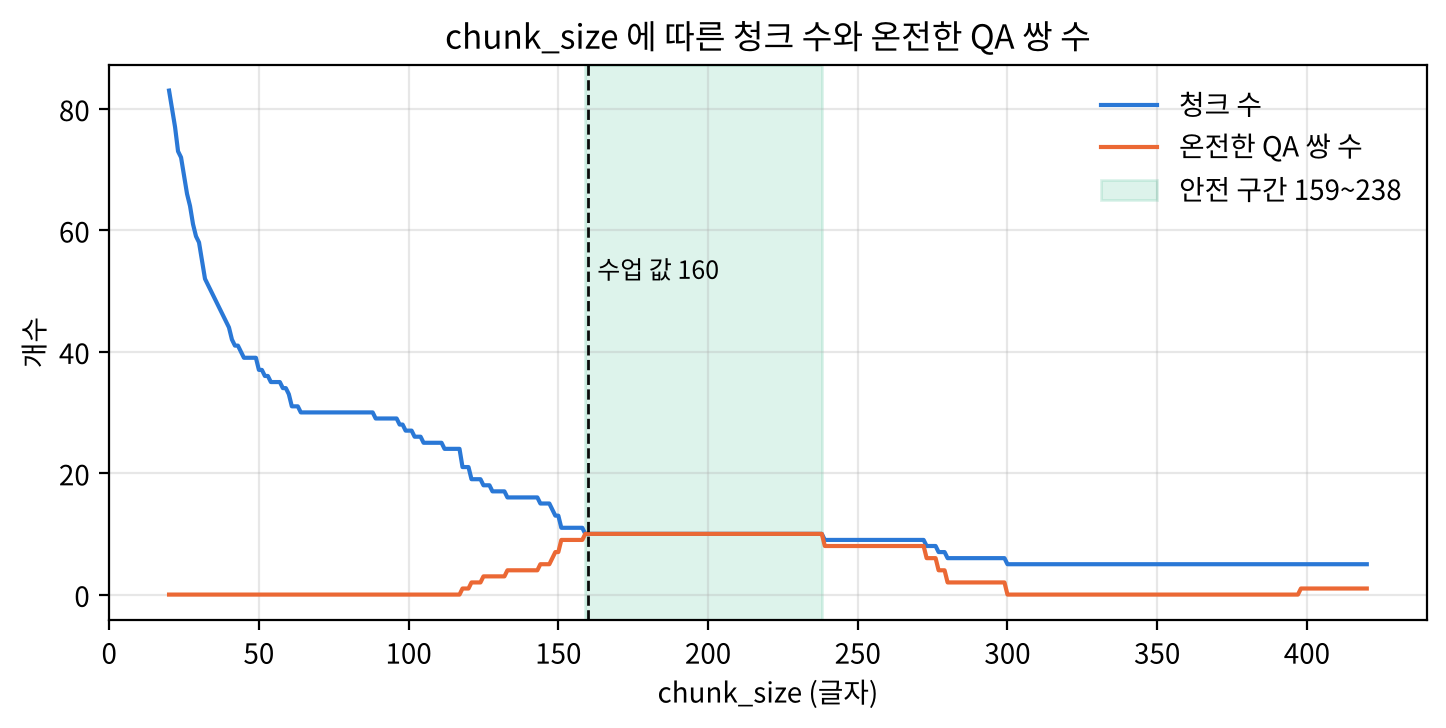

In [20]:
# 경계가 정확히 어디인지 1씩 바꿔 가며 찾는다
sweep = pd.DataFrame([split_stats(s) for s in range(20, 421)]).set_index('chunk_size')
ok = sweep[(sweep['청크 수'] == 10) & (sweep['온전한 QA 쌍'] == 10)]             # QA 1쌍 = 청크 1개가 되는 구간
print(f'QA 1쌍 = 청크 1개 가 되는 chunk_size : {ok.index.min()} ~ {ok.index.max()} ({len(ok)}개 값)')

fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.plot(sweep.index, sweep['청크 수'], color='#2a78d6', label='청크 수')
ax.plot(sweep.index, sweep['온전한 QA 쌍'], color='#eb6834', label='온전한 QA 쌍 수')
ax.axvspan(ok.index.min(), ok.index.max(), color='#1baf7a', alpha=0.15, label=f'안전 구간 {ok.index.min()}~{ok.index.max()}')
ax.axvline(160, color='#0b0b0b', lw=1, ls='--')                              # 수업 값
ax.text(163, 52, '수업 값 160', fontsize=9)
ax.set_xlabel('chunk_size (글자)'); ax.set_ylabel('개수'); ax.set_title('chunk_size 에 따른 청크 수와 온전한 QA 쌍 수')
ax.legend(frameon=False); ax.grid(alpha=0.3)
plt.show()

![chunk_size 변화 애니메이션](./images/anim_04_chunk_size_sweep.gif)

### 왜 157 이 아니라 159 부터인가 — 구분자가 조각에 붙어 있다

`RecursiveCharacterTextSplitter` 의 기본값은 `keep_separator=True` 다. `\n\n` 으로 자를 때 구분자를 버리지 않고 **뒤 조각의 맨 앞에 붙여 둔 채** 길이를 잰다. 그래서 157자짜리 쌍은 157 + 2 = **159자**로 계산된다(최종 청크에서는 앞뒤 공백이 지워져 다시 157자).

In [21]:
# keep_separator 에 따라 '10개가 되기 시작하는 chunk_size' 가 달라지는지 확인
for keep in [True, False]:
    counts = {s: split_stats(s, keep_separator=keep)['청크 수'] for s in [156, 157, 158, 159, 160]}
    first_ok = min(s for s, n in counts.items() if n == 10)
    print(f'keep_separator={keep!s:5s} → {counts} → 10개가 되는 첫 값 : {first_ok}')

# 구분자를 붙인 채로 잰 조각 길이 (첫 조각만 구분자가 없다)
print('구분자 포함 길이 :', [len(p) + (2 if i > 0 else 0) for i, p in enumerate(qa_pairs)])

keep_separator=True  → {156: 11, 157: 11, 158: 11, 159: 10, 160: 10} → 10개가 되는 첫 값 : 159
keep_separator=False → {156: 11, 157: 10, 158: 10, 159: 10, 160: 10} → 10개가 되는 첫 값 : 157
구분자 포함 길이 : [133, 144, 148, 125, 159, 121, 118, 151, 151, 149]


- `keep_separator=False` 로 구분자를 버리면 예상대로 **157** 부터 10개가 된다 → 원인은 구분자 2글자
- 위쪽 경계 238 도 같은 이유다 : 6 · 7번째 쌍이 (119 + 2) + (116 + 2) = **239** 로 계산돼 239 부터 합쳐진다
- 4장에서 `chunk_size=150` 일 때 149자짜리 8 · 9번째 쌍까지 잘린 것도 149 + 2 = 151 > 150 이기 때문

**결론** — '가장 긴 쌍 157자 → 160' 은 맞는 값이지만 여유가 **1** 뿐이다(159 부터 가능). 매뉴얼에 158자 넘는 쌍이 하나만 추가돼도 그 쌍은 갈라진다. `chunk_size` 는 `최대 길이 + 구분자 길이` 보다 넉넉히, 두 쌍이 합쳐지는 값(239)보다 작게 — 이 데이터라면 **200** 정도가 안전하다. 그리고 값을 정한 뒤에는 4장처럼 **결과를 코드로 검증**한다.

### `chunk_overlap` — 이 데이터에서는 0 이든 40 이든 같다

In [22]:
# 이웃한 두 청크가 실제로 몇 글자 겹치는지 세는 함수
def overlap_lengths(texts):
    result = []
    for a, b in zip(texts, texts[1:]):
        n = next((k for k in range(min(len(a), len(b)), 0, -1) if a.endswith(b[:k])), 0)   # a 의 끝 = b 의 시작인 가장 긴 길이
        result.append(n)
    return result

for size, overlap in [(160, 0), (160, 20), (160, 40), (80, 0), (80, 20)]:
    texts = RecursiveCharacterTextSplitter(chunk_size=size, chunk_overlap=overlap).split_text(manual_text)
    ov = overlap_lengths(texts)
    print(f'chunk_size={size:3d} overlap={overlap:2d} → 청크 {len(texts):2d}개 | 실제로 겹친 곳 {sum(n > 0 for n in ov):2d}군데 | 겹친 글자 수 {[n for n in ov if n > 0]}')

chunk_size=160 overlap= 0 → 청크 10개 | 실제로 겹친 곳  0군데 | 겹친 글자 수 []
chunk_size=160 overlap=20 → 청크 10개 | 실제로 겹친 곳  0군데 | 겹친 글자 수 []
chunk_size=160 overlap=40 → 청크 10개 | 실제로 겹친 곳  0군데 | 겹친 글자 수 []
chunk_size= 80 overlap= 0 → 청크 30개 | 실제로 겹친 곳  0군데 | 겹친 글자 수 []
chunk_size= 80 overlap=20 → 청크 30개 | 실제로 겹친 곳 10군데 | 겹친 글자 수 [17, 18, 16, 19, 14, 19, 17, 15, 18, 17]


- `chunk_size=160` 에서는 `chunk_overlap` 을 20 · 40 으로 줘도 **겹치는 곳이 없다.** 겹침은 '앞 청크의 마지막 조각들' 을 다음 청크 앞에 다시 넣는 방식인데, 여기서는 조각 하나가 QA 한 쌍(116자 이상)이라 20 ~ 40자 안에 들어갈 조각이 없다
- `chunk_size=80` 처럼 공백 단위까지 잘게 잘릴 때 비로소 겹침이 생긴다(요청한 20자 이하로, 단어 경계에 맞춰)
- 메모의 'QA · 법률은 overlap = 0, 일반 소설은 `chunk_size` 의 10%' 는 **경험칙**이다. QA 처럼 조각끼리 내용이 독립이면 겹칠 이유가 없고, 이야기처럼 문맥이 이어지는 글은 경계에서 끊긴 문장을 양쪽 청크에 남겨 두려고 겹친다

## 6. 글자 수 vs 토큰 수 — '8,192 토큰 제한' 은 이 데이터와 상관이 있나

메모 : '임베딩 모델이 한 번에 처리할 수 있는 입력 길이 제한(**8,192 토큰**)을 고려하여 긴 문서를 작은 조각으로 분할'. 제한은 **토큰**, `chunk_size` 는 **글자** — 단위가 다르다.

In [23]:
# 매뉴얼 전체와 청크의 토큰 수
EMBED_LIMIT = 8192                                           # OpenAI 임베딩 모델의 입력 1건 최대 토큰 (API 문서)
total_tokens = len(enc.encode(manual_text))
chunk_tokens = [len(enc.encode(c.page_content)) for c in chunks]

print(f'매뉴얼 전체 : {len(manual_text):,}자 = {total_tokens:,} 토큰 → 제한의 {total_tokens / EMBED_LIMIT:.1%}')
print(f'청크 10개   : 토큰 {min(chunk_tokens)} ~ {max(chunk_tokens)} (가장 큰 청크도 제한의 {max(chunk_tokens) / EMBED_LIMIT:.1%})')
print(f'전체가 한 번에 들어가는가 : {total_tokens <= EMBED_LIMIT}')

매뉴얼 전체 : 1,399자 = 1,291 토큰 → 제한의 15.8%
청크 10개   : 토큰 105 ~ 159 (가장 큰 청크도 제한의 1.9%)
전체가 한 번에 들어가는가 : True


매뉴얼 **전체가 1,291 토큰**으로 제한의 16% 다. 자르지 않아도 임베딩 한 번에 들어간다. 그러니 이 실습에서 분할하는 진짜 이유는 입력 제한이 아니라 **검색 정확도**다 — 문서를 통째로 벡터 1개로 만들면 어떤 질문이든 같은 문서(전체)가 나온다. QA 한 쌍씩 벡터를 만들어야 질문과 가까운 **한 쌍만** 골라낼 수 있다. (개요 노트 5장에서 `chunk_size` 100 · 160 · 300 · 4000 의 검색 결과를 비교한다.)

길이를 토큰으로 재고 싶으면 `from_tiktoken_encoder` 로 만든다.

In [24]:
# 토큰 기준 분할 도구 — chunk_size 의 단위가 '토큰' 이 된다
for token_size in [160, 200]:
    token_splitter = RecursiveCharacterTextSplitter.from_tiktoken_encoder(
        encoding_name='cl100k_base',      # 임베딩 모델과 같은 토크나이저로 길이를 잰다
        chunk_size=token_size,            # 단위 : 토큰
        chunk_overlap=0,
    )
    token_chunks = token_splitter.split_text(manual_text)
    print(f'chunk_size={token_size} 토큰 → 청크 {len(token_chunks)}개 | 온전한 QA 쌍 {sum(t in qa_pairs for t in token_chunks)}개')

chunk_size=160 토큰 → 청크 11개 | 온전한 QA 쌍 9개
chunk_size=200 토큰 → 청크 10개 | 온전한 QA 쌍 10개


같은 숫자 160 이라도 **토큰 기준이면 11개**로 갈라진다(5번째 쌍이 159 토큰 + 구분자). 숫자만 옮기면 안 되고 단위를 확인해야 한다.

## 7. 구조를 아는 데이터는 구조대로 — QA 쌍으로 직접 `Document` 만들기

이 매뉴얼은 '빈 줄 = 쌍의 경계' 라는 것을 이미 안다. 그렇다면 `chunk_size` 를 맞추는 대신 **쌍 단위로 직접** `Document` 를 만들 수 있다. 길이가 얼마든 갈라지거나 합쳐지지 않고, `metadata` 에 번호 · 질문을 넣어 출처 표시에 쓸 수 있다.

In [25]:
from langchain_core.documents import Document

qa_documents = [
    Document(
        page_content=pair,                                             # QA 한 쌍 그대로
        metadata={
            'source': manual_path,                                     # 어느 파일
            'qa_id': number,                                           # 몇 번째 쌍
            'question': pair.split('\n')[0].removeprefix('질문: '),      # 질문 줄
        },
    )
    for number, pair in enumerate(qa_pairs, 1)
]

print('문서 수 :', len(qa_documents))
print('분할 도구 결과와 내용이 같은가 :', [d.page_content for d in qa_documents] == [c.page_content for c in chunks])
print(qa_documents[1].metadata)

문서 수 : 10
분할 도구 결과와 내용이 같은가 : True
{'source': 'manual.txt', 'qa_id': 2, 'question': '수강 신청한 강의를 환불하고 싶어요. 환불 정책은 어떻게 되나요?'}


In [26]:
# 분할 도구를 쓰면서 위치 정보를 남기려면 add_start_index=True (원문에서 몇 번째 글자부터인지)
index_splitter = RecursiveCharacterTextSplitter(chunk_size=160, chunk_overlap=0, add_start_index=True)
index_chunks = index_splitter.split_documents(documents)
print([c.metadata['start_index'] for c in index_chunks])
start = index_chunks[4].metadata['start_index']                          # 5번째 청크의 시작 위치
print('원문에서 다시 꺼내 본 5번째 청크 :', manual_text[start:start + 29])

[0, 135, 279, 427, 552, 711, 832, 950, 1101, 1252]
원문에서 다시 꺼내 본 5번째 청크 : 질문: 강의 동영상이 자꾸 끊기거나 재생되지 않아요.


## 📝 고친 부분 정리

| 위치 | 원본 | 고친 내용 |
|---|---|---|
| 필기 cell 4 | `TextLoader(file_path)` — `file_path` 는 `.env` 경로 | **매뉴얼 대신 `.env` 를 읽어 API 키 2개가 출력에 저장됨** → 경로 변수 분리(`manual_path`) · 불러온 직후 `assert` · 키는 폐기 후 재발급 · 올린 원본은 키 값 가림 |
| 필기 cell 2 · 강의본 cell 5 | `C:\Users\…` 절대 경로 | 상대 경로 `'manual.txt'` · `find_dotenv(usecwd=True)` |
| 필기 cell 6 | `max(qa_pairs)` 를 '가장 긴 QA 단락의 글자 수' 로 출력 | 사전 순 최댓값(8번째 · 149자)이 나옴 → `max(len(p) for p in qa_pairs)` = **157**(5번째) |
| 필기 cell 6 | 변수 `menu_text` · `print(type(string_txt))` | `manual_text` · 불필요한 출력 삭제 · `for + append` → `split()` 결과를 그대로 사용 |
| 필기 cell 7 | `#단어 출력` `for out in string_txt: qa_pairs.append(out)` | 글자 147개가 `qa_pairs` 에 붙어 157개가 됨(실행 순서 때문에 출력만 멀쩡) → 삭제 · 단어는 `split()` |
| 필기 · 강의본 | 파일을 `TextLoader` 와 `open()` 으로 두 번 읽음 | `documents[0].page_content` 를 그대로 사용 |
| 필기 · 강의본 | 분할 도구를 만들고 끝 | `split_documents()` 실행 → 청크 10개 = QA 10쌍 검증 |
| 메모 | '`\n` 문장' | `\n` 은 줄바꿈. 문장 끝은 기본 구분자에 없음 |
| 메모 | '`chunk_size` 보다 짧으면 병합' | 합쳐도 `chunk_size` 를 넘지 않을 때만 이어 붙임 |
| 메모 | '`load()` · `split_documents()` 는 전용 함수' | `BaseLoader` · `TextSplitter` 의 공통 함수 |
| 메모 | '입력 길이 제한(8,192 토큰)을 고려하여 분할' | 매뉴얼 전체가 1,291 토큰 — 이 실습의 분할 이유는 **검색 정확도**. 제한은 토큰 · `chunk_size` 는 글자 |
| 수업 값 | `chunk_size=160` (최대 157자) | 맞는 값이지만 가능한 구간 159 ~ 238 의 맨 아래 → 구분자 2글자를 더해 계산하고 여유를 둔다 |
| 필기 cell 1 | `FAISS` · `OpenAIEmbeddings` 임포트 | 오늘 범위에서 쓰지 않음 → 다음 단계에서 |

## 정리

| 단계 | 코드 | 결과 |
|---|---|---|
| 불러오기 | `TextLoader('manual.txt', encoding='utf-8').load()` | `[Document]` 1개 · 1,399자 · `metadata={'source': …}` |
| 길이 재기 | `[len(p) for p in text.split('\n\n')]` | QA 10쌍 · 116 ~ **157**자 (123 ~ 159 토큰) |
| 분할 도구 | `RecursiveCharacterTextSplitter(chunk_size=160, chunk_overlap=0)` | 구분자 `\n\n` → `\n` → 공백 → 글자 |
| 분할 | `text_splitter.split_documents(documents)` | 청크 10개 = QA 10쌍 |
| 검증 | `all(c.page_content == p for c, p in zip(chunks, qa_pairs))` | `True` |

다음 단계(교재 p.39 과정 ③ ~) : 청크 10개 → **임베딩**(`OpenAIEmbeddings`) → **벡터 저장소**(`FAISS`) → 검색 도구 → 프롬프트 + LLM → RAG 체인.